<a href="https://colab.research.google.com/github/charliecapretta/NBA-Prediction-Project/blob/main/PlayerGrouping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
import pandas as pd

df = pd.read_csv("/content/nba_player_seasons_clean.csv")
df.head()



,Player,WS,G,MP,Season,Age,Team,GS,AS,FG,...,TOVPG,FGAPG,2PAPG,3PAPG,FTAPG,ORPG,DRPG,Player_Key,All_NBA,All_NBA_Team
0,James Harden,15.2,78,2867,2018-19,29,HOU,78,1,843,...,4.961538,24.474359,11.294872,13.179487,11.000000,0.846154,5.794872,james harden,1,1
1,Rudy Gobert,14.4,81,2577,2018-19,26,UTA,80,0,476,...,1.604938,8.790123,8.790123,0.000000,6.444444,3.814815,9.037037,rudy gobert,1,3
2,Giannis Antetokounmpo,14.4,72,2358,2018-19,24,MIL,72,1,721,...,3.722222,17.319444,14.500000,2.819444,9.527778,2.208333,10.263889,giannis antetokounmpo,1,1
3,Damian Lillard,12.1,80,2838,2018-19,28,POR,80,1,681,...,2.650000,19.162500,11.125000,8.037500,6.412500,0.850000,3.787500,damian lillard,1,2
4,Paul George,11.9,77,2841,2018-19,28,OKC,77,1,707,...,2.662338,20.961039,11.129870,9.831169,7.012987,1.363636,6.792208,paul george,1,1


## Create features for PCA algorithm

# Shots per 36

FGA / MP * 36

High-usage scorers from low-usage role players

# 3 point rate

3PA / FGA

Perimeter shooters from interior players

# Free Throw rate

FTA / FGA

Players who attack the rim and draw fouls

# True Shooting%

TS%

Efficient finishers from volume shooters

# FT%

FT%

Pure shooters from poor-shooting bigs

# Assists per 39

AST / MP * 36

Creators from finishers

# Offensive Rebounds per 39

ORB / MP * 36

Bigs who crash the offensive glass

# Defensive Rebounds per 39

DRB / MP * 36

Bigs who crash the Defensive glass

# Steals per 36

STL / MP * 36

Perimeter defenders

# Blocks per 36

BLK / MP * 36

Interior defenders

In [48]:
df["ShotsPer36"] = (df["FGA"] / df["MP"]) * 36

df["3PointRate"] = (df["3PA"] / df["FGA"])

df["FreeThrowRate"] = (df["FTA"] / df["FGA"])

df["AssistPer36"] = (df["AST"] / df["MP"]) * 36

df["OffensiveReboundPer36"] = (df["ORB"] / df["MP"]) * 36

df["DefensiveReboundPer36"] = (df["DRB"] / df["MP"]) * 36

df["StealPer36"] = (df["STL"] / df["MP"]) * 36

df["BlockPer36"] = (df["BLK"] / df["MP"]) * 36


features = ["ShotsPer36", "3PointRate", "FreeThrowRate", "AssistPer36", "OffensiveReboundPer36", "DefensiveReboundPer36", "StealPer36", "BlockPer36", "TS%", "FT%"]
featuredf = df[features]

featuredf.head()


,ShotsPer36,3PointRate,FreeThrowRate,AssistPer36,OffensiveReboundPer36,DefensiveReboundPer36,StealPer36,BlockPer36,TS%,FT%
0,23.970701,0.538502,0.449450,7.358214,0.828741,5.675619,1.983955,0.728287,0.616,0.879
1,9.946449,0.000000,0.733146,2.249127,4.316647,10.225844,0.922002,2.612340,0.682,0.636
2,19.038168,0.162791,0.550120,6.473282,2.427481,11.282443,1.404580,1.679389,0.644,0.729
3,19.446089,0.419439,0.334638,6.989429,0.862579,3.843552,1.116279,0.431290,0.588,0.912
4,20.451954,0.469021,0.334572,4.029567,1.330517,6.627244,2.154171,0.430834,0.583,0.839


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaledFeatures = scaler.fit_transform(df[features])

scaledFeatures_df = pd.DataFrame(scaledFeatures, columns=features, index=df.index)

scaledFeatures_df.head()

,ShotsPer36,3PointRate,FreeThrowRate,AssistPer36,OffensiveReboundPer36,DefensiveReboundPer36,StealPer36,BlockPer36,TS%,FT%
0,2.751293,0.808148,1.510666,1.608858,-0.694961,0.113309,2.098151,-0.143767,0.559297,1.078103
1,-0.885581,-1.733398,3.861372,-0.740387,1.912595,2.225220,-0.550506,2.606867,2.130065,-1.559186
2,1.472151,-0.965081,2.344820,1.201951,0.500256,2.715623,0.653110,1.244800,1.225684,-0.549853
3,1.577937,0.246211,0.559333,1.439284,-0.669663,-0.737015,-0.065953,-0.577370,-0.107089,1.436253
4,1.838785,0.480222,0.558791,0.078289,-0.319833,0.554989,2.522693,-0.578035,-0.226087,0.643981


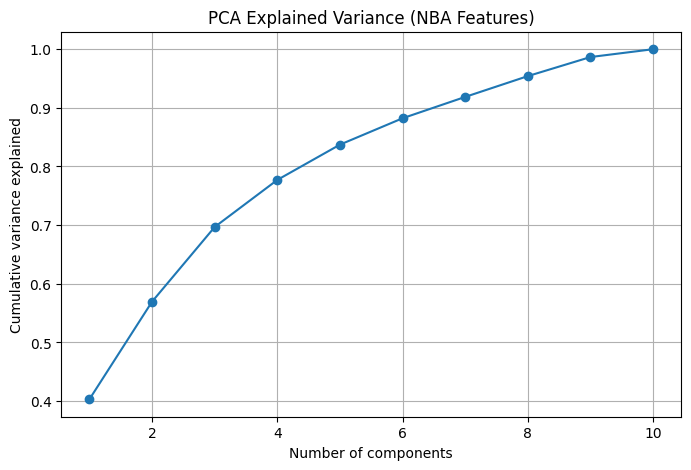

,PC1,PC2,PC3
ShotsPer36,-0.16,0.54,-0.31
3PointRate,-0.38,-0.33,-0.07
FreeThrowRate,0.30,0.40,-0.16
AssistPer36,-0.20,0.59,0.14
OffensiveReboundPer36,0.46,-0.02,0.09
DefensiveReboundPer36,0.38,0.17,-0.06
StealPer36,-0.10,0.21,0.70
BlockPer36,0.39,-0.07,0.04
TS%,0.27,-0.08,-0.42
FT%,-0.35,0.09,-0.42


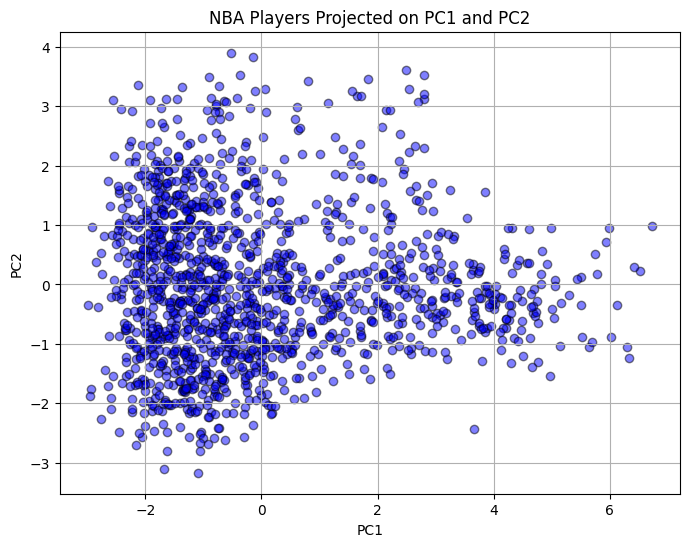

In [50]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA()
nbaComponents = pca.fit_transform(scaledFeatures)

# 1. How much of the variation does each component capture?
explained = pca.explained_variance_ratio_
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained) + 1), explained.cumsum(), marker="o")
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance explained")
plt.title("PCA Explained Variance (NBA Features)")
plt.grid(True)
plt.show()

# 2. What is each component made of?
loadings = pd.DataFrame(pca.components_.T,
                        index=features,
                        columns=[f"PC{i+1}" for i in range(len(features))])
display(loadings[["PC1", "PC2", "PC3"]].round(2))

# 3. Plot the rows on the first two components
plt.figure(figsize=(8, 6))
plt.scatter(nbaComponents[:, 0], nbaComponents[:, 1], alpha=0.5, c='blue', edgecolors='k')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("NBA Players Projected on PC1 and PC2")
plt.grid(True)
plt.show()

Variance explained by first two components combined: 56.95%
Number of components to reach at least 80% variance: 5



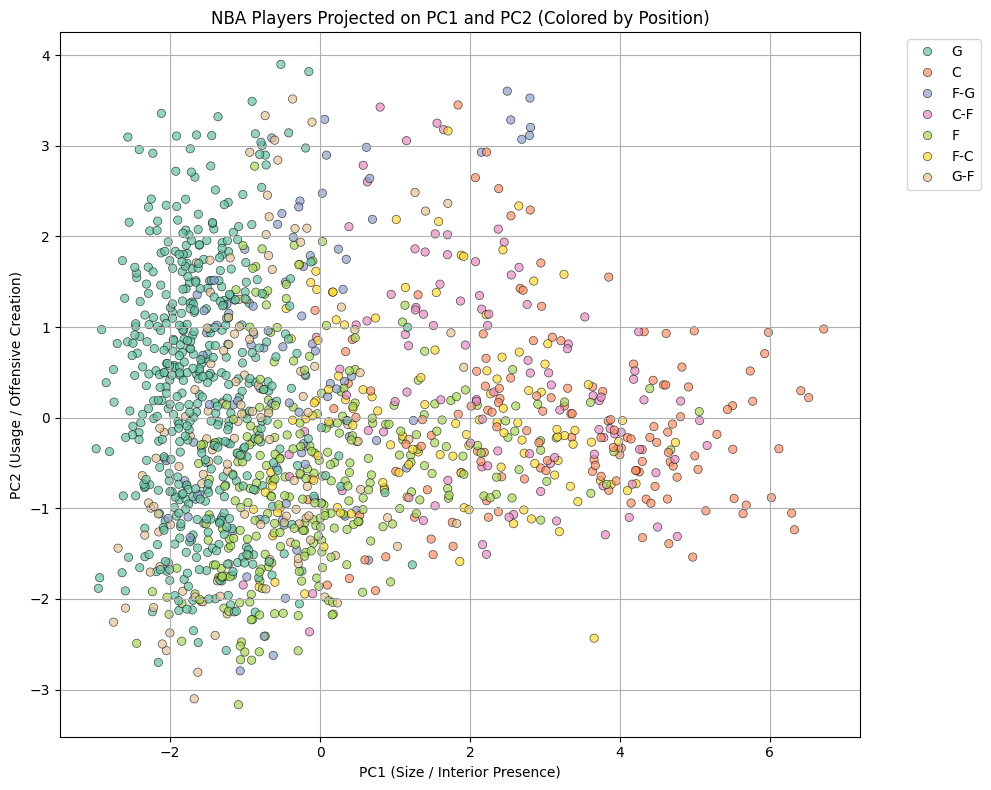

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate cumulative variance
cum_var = explained.cumsum()
print(f"Variance explained by first two components combined: {cum_var[1]:.2%}")

# Find how many components to reach ~80%
n_comp_80 = next(i+1 for i, val in enumerate(cum_var) if val >= 0.80)
print(f"Number of components to reach at least 80% variance: {n_comp_80}\n")

# Create a DataFrame with PCA coordinates and the original position ('Pos') column
pca_df = pd.DataFrame(nbaComponents[:, :2], columns=['PC1', 'PC2'])
pca_df['Pos'] = df['Pos'].values

# Plot PC1 vs PC2 colored by position
plt.figure(figsize=(10, 8))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Pos', alpha=0.7, palette='Set2', edgecolor='k')
plt.title("NBA Players Projected on PC1 and PC2 (Colored by Position)")
plt.xlabel("PC1 (Size / Interior Presence)")
plt.ylabel("PC2 (Usage / Offensive Creation)")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Evaluating Groups and Positions (Adapted from Resources)

In [52]:
# Sample members of one position group (e.g., Guards 'G')
df[df["Pos"] == "G"][["Player", "Team", "MP", "PTS"]].sample(10, random_state=42)

,Player,Team,MP,PTS
1265,Scotty Pippen Jr.,MEM,1683,779
243,Bradley Beal,WAS,2053,1741
893,CJ McCollum,NOP,2649,1568
515,Dejounte Murray,SAS,2139,1051
940,Coby White,CHI,1730,715
579,Garrison Mathews,WAS,1038,354
464,Delon Wright,"DET,SAC",1748,645
179,Gary Harris,DEN,1639,737
919,Alex Caruso,CHI,1575,374
40,Darren Collison,IND,2143,853


In [53]:
# Show cross-tabulation of position vs. other categorical identifiers if available
pd.crosstab(df["Pos"], df["All_NBA"])

All_NBA,0,1
Pos,,
C,138,7
C-F,95,11
F,285,9
F-C,109,8
F-G,67,23
G,456,38
G-F,118,9
